# HMC-NNN Datalab — Opnameduur voorspellen: de meetlat

**Minor Data & Health Innovation · HMC-NNN**

Derde en laatste notebook van de basispijplijn, na
[`01_base_eda_hmc_nnn.ipynb`](01_base_eda_hmc_nnn.ipynb) en
[`02_feature_engineering.ipynb`](02_feature_engineering.ipynb).

## Wat dit notebook wél en niet is

Dit notebook levert **geen werkend voorspelmodel**. Dat kan ook niet: de testset heeft
10 opnames en 22 kolommen — meer kolommen dan rijen. Elk model dat je hierop traint, past zich
aan de ruis aan.

Wat het wél levert is de **meetlat**: een evaluatieopzet die klopt en die straks op de
volledige HMC-dataset (~25.000 opnames) ongewijzigd draait. Die opzet is belangrijker dan
hij klinkt, want bij drie groepsleden met drie eigen splitsingen zijn resultaten niet meer
te vergelijken.

Drie dingen liggen daarom vast in `src/modellering.py`:

1. **Drie benoemde featuresets** — `icd10`, `nanda_noc` en `beide`. Het verschil tussen de
   eerste en de laatste is precies de onderzoeksvraag: voegt het zorgplan iets toe bovenop
   de medische diagnose?
2. **Cross-validatie gegroepeerd op patiënt** — dezelfde patiënt zit nooit in train en test
   tegelijk, en de voorbewerking gebeurt binnen elke fold.
3. **Een verplichte baseline** die altijd de mediane opnameduur voorspelt. Een model dat
   daar niet overheen komt, voegt niets toe.

> **N = 10.** Lees de getallen hieronder als een demonstratie van de methode, niet als een
> uitkomst. De conclusie onderaan zegt precies wat je er wel en niet uit mag halen.

## 0. Setup

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import MaxNLocator
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge


def vind_project_root() -> Path:
    """Zoekt omhoog vanaf de huidige map tot src/data_loader.py gevonden is."""
    for kandidaat in [Path.cwd(), *Path.cwd().parents]:
        if (kandidaat / "src" / "data_loader.py").is_file():
            return kandidaat
    raise FileNotFoundError(
        "Kan de project-root niet vinden: src/data_loader.py ontbreekt in deze map "
        "en in alle bovenliggende mappen."
    )


PROJECT_ROOT = vind_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.features import controleer_geen_leakage
from src.modellering import (
    DOELVARIABELE,
    FEATURESETS,
    bouw_featureset,
    evalueer_model,
    vergelijk_modellen,
)

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)

print("Project-root:", PROJECT_ROOT)

Project-root: C:\Users\qsoerohardjo\Documents\hmc-nnn


In [2]:
# Zelfde huisstijl als notebook 01 en 02.
SURFACE = "#fcfcfb"
INK = "#0b0b0b"
INK_SECUNDAIR = "#52514e"
GRID = "#e1e0d9"
AS = "#c3c2b7"

PALET = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
         "#e87ba4", "#008300", "#6250d6", "#e34948"]
BLAUW, ORANJE, AQUA = PALET[0], PALET[1], PALET[2]
NEUTRAAL = "#c9c8c1"

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "figure.dpi": 110,
    "savefig.facecolor": SURFACE,
    "savefig.bbox": "tight",
    "axes.facecolor": SURFACE,
    "axes.edgecolor": AS,
    "axes.linewidth": 0.8,
    "axes.labelcolor": INK_SECUNDAIR,
    "axes.titlecolor": INK,
    "axes.titlesize": 11.5,
    "axes.titleweight": "semibold",
    "axes.titlelocation": "left",
    "axes.titlepad": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False,
    "axes.axisbelow": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "grid.linestyle": "-",
    "xtick.color": AS,
    "ytick.color": AS,
    "xtick.labelcolor": INK_SECUNDAIR,
    "ytick.labelcolor": INK_SECUNDAIR,
    "font.family": "sans-serif",
    "font.sans-serif": ["Segoe UI", "DejaVu Sans", "Arial"],
    "font.size": 10,
    "lines.linewidth": 2,
    "lines.markersize": 8,
    "legend.frameon": False,
    "legend.fontsize": 9,
})


def stijl_as(ax, waarde_as="y"):
    ax.grid(axis=waarde_as, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    return ax


def hele_dagen(ax, as_naam="x"):
    as_object = ax.xaxis if as_naam == "x" else ax.yaxis
    as_object.set_major_locator(MaxNLocator(integer=True))
    return ax

---

## 1. De modelleertabel inladen

Notebook 02 heeft de tabel weggeschreven naar `data/processed/`. Staat dat bestand er niet
(bijvoorbeeld omdat je net de repo hebt gekloond), dan bouwen we hem opnieuw op uit de bron.

In [3]:
tabel_pad = PROJECT_ROOT / "data" / "processed" / "modelleertabel_dag0.csv"

if tabel_pad.is_file():
    modelleertabel = pd.read_csv(tabel_pad)
    print(f"Ingelezen: {tabel_pad.relative_to(PROJECT_ROOT)}")
else:
    from src.data_loader import load_and_clean_hmc_data
    from src.features import build_dag0_diagnose_dummies, build_dag0_features

    df = load_and_clean_hmc_data()
    modelleertabel = build_dag0_features(df).merge(
        build_dag0_diagnose_dummies(df), on="Opnamenummer"
    )
    print("Bestand niet gevonden; opnieuw opgebouwd vanuit de bron.")

print(f"{modelleertabel.shape[0]} opnames x {modelleertabel.shape[1]} kolommen")

# Dezelfde controle als in notebook 02: niets uit de toekomst in de tabel.
controleer_geen_leakage(modelleertabel)
print("Leakage-controle: geslaagd.")

Ingelezen: data\processed\modelleertabel_dag0.csv
10 opnames x 27 kolommen
Leakage-controle: geslaagd.


### De drie featuresets

`bouw_featureset()` kiest de kolommen. Sleutels (`Opnamenummer`, `Patientnr`), labels
(`ICD10Code`, `ICD10Omschrijving`) en de doelvariabele vallen er altijd buiten — die mogen
nooit per ongeluk als feature meeliften.

In [4]:
overzicht = []
for naam in FEATURESETS:
    X, numeriek, categorisch = bouw_featureset(modelleertabel, naam)
    overzicht.append({
        "featureset": naam,
        "kolommen": X.shape[1],
        "numeriek": len(numeriek),
        "categorisch": len(categorisch),
        "voorbeelden": ", ".join(list(X.columns)[:4]) + (" ..." if X.shape[1] > 4 else ""),
    })

pd.DataFrame(overzicht)

,featureset,kolommen,numeriek,categorisch,voorbeelden
0,icd10,1,0,1,icd10_hoofdcode
1,nanda_noc,21,21,0,"heeft_dag0_meting, n_metingen_dag0, n_diagnose..."
2,beide,22,21,1,"icd10_hoofdcode, heeft_dag0_meting, n_metingen..."


Let op de verhouding: `beide` heeft **22 kolommen voor 10 rijen**. Dat is geen detail maar de
kern van waarom dit notebook geen model oplevert — met meer knoppen dan waarnemingen kan een
model elke trainingsset perfect namaken zonder iets geleerd te hebben.

---

## 2. De baseline: altijd de mediaan

Voordat je een model beoordeelt, moet je weten wat "niets doen" oplevert. Voor een scheve
verdeling als opnameduur is dat de **mediaan**: die minimaliseert de gemiddelde absolute fout
als je verder niets weet.

Elk model moet hieronder komen. Lukt dat niet, dan voegt het niets toe — hoe geavanceerd het
ook is.

In [5]:
y = modelleertabel[DOELVARIABELE]
print(f"Opnameduur: mediaan {y.median():.1f} dagen, gemiddelde {y.mean():.1f} dagen, "
      f"spreiding {y.min()}-{y.max()} dagen")

baseline = evalueer_model(modelleertabel, "beide", DummyRegressor(strategy="median"))
print()
print(f"Mediaan-baseline over {baseline['n_folds']} folds:")
print(f"  MAE  = {baseline['MAE_dagen']:.2f} dagen")
print(f"  RMSE = {baseline['RMSE_dagen']:.2f} dagen")
print(f"  R2   = {baseline['R2']:.3f}")

Opnameduur: mediaan 6.5 dagen, gemiddelde 6.6 dagen, spreiding 0-13 dagen



Mediaan-baseline over 10 folds:
  MAE  = 3.70 dagen
  RMSE = 4.25 dagen
  R2   = -0.236


Een MAE van ongeveer 3,7 dagen betekent: wie altijd de mediaan noemt, zit er gemiddeld bijna
vier dagen naast. Dat is het getal dat de modellen moeten verslaan.

De R² is negatief. Dat is geen fout: R² vergelijkt met het gemiddelde van de **testdata**, en
bij leave-one-out is dat per fold één waarde. Een negatieve R² betekent simpelweg "slechter
dan domweg het gemiddelde voorspellen". Bij deze N is dat te verwachten; kijk hier vooral naar
MAE in dagen, die is tenminste uit te leggen.

---

## 3. Drie modellen, drie featuresets

Nu draaien we alle negen combinaties. De evaluatie is voor elke combinatie identiek:
leave-one-patient-out, voorbewerking binnen de fold, metrieken over de verzamelde
out-of-fold voorspellingen.

- **Mediaan-baseline** — negeert de features volledig
- **Ridge** — lineair met regularisatie, de enige lineaire variant die bij meer kolommen dan
  rijen niet ontspoort
- **RandomForest** — krachtiger, en juist daarom leerzaam om te zien hoe het hier afloopt

In [6]:
modellen = {
    "Mediaan-baseline": DummyRegressor(strategy="median"),
    "Ridge": Ridge(alpha=1.0),
    "RandomForest": RandomForestRegressor(n_estimators=200, random_state=42),
}

resultaten, details = vergelijk_modellen(modelleertabel, modellen)
resultaten

,model,featureset,n_features,MAE_dagen,RMSE_dagen,R2
0,Mediaan-baseline,icd10,1,3.70,4.25,-0.236
1,Mediaan-baseline,nanda_noc,21,3.70,4.25,-0.236
2,Mediaan-baseline,beide,22,3.70,4.25,-0.236
3,Ridge,icd10,1,3.90,4.42,-0.333
4,RandomForest,nanda_noc,21,3.92,4.35,-0.294
5,RandomForest,beide,22,4.06,4.42,-0.333
6,RandomForest,icd10,1,4.16,4.72,-0.522
7,Ridge,beide,22,4.38,4.81,-0.580
8,Ridge,nanda_noc,21,4.55,4.96,-0.681


De baseline scoort voor alle drie de featuresets exact hetzelfde. Dat hoort zo — hij kijkt
niet naar de features — en het is meteen een nuttige controle: zie je daar wél verschil, dan
zit er iets fout in de evaluatie.

In [7]:
baseline_mae = resultaten.loc[resultaten["model"] == "Mediaan-baseline", "MAE_dagen"].iloc[0]
getraind = resultaten[resultaten["model"] != "Mediaan-baseline"]
beter = getraind[getraind["MAE_dagen"] < baseline_mae]

print(f"Baseline MAE: {baseline_mae:.2f} dagen")
print(f"Getrainde modellen die daar onder komen: {len(beter)} van de {len(getraind)}")
print()
if beter.empty:
    print("Geen enkel model verslaat de mediaan. Bij 10 opnames en 22 kolommen is dat")
    print("precies wat je verwacht: er valt niets te leren, dus leert een model ruis.")
else:
    print(beter.to_string(index=False))

Baseline MAE: 3.70 dagen
Getrainde modellen die daar onder komen: 0 van de 6

Geen enkel model verslaat de mediaan. Bij 10 opnames en 22 kolommen is dat
precies wat je verwacht: er valt niets te leren, dus leert een model ruis.


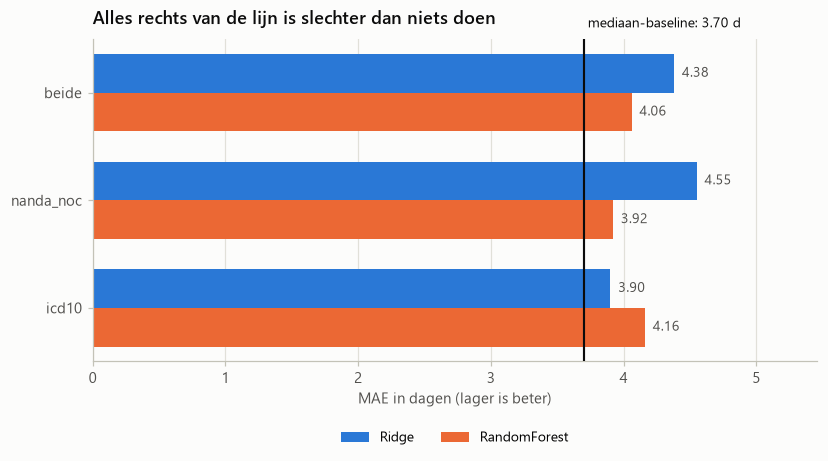

In [8]:
volgorde = list(FEATURESETS)
modelnamen = ["Ridge", "RandomForest"]
kleuren = {"Ridge": BLAUW, "RandomForest": ORANJE}

y_pos = np.arange(len(volgorde))
hoogte = 0.36

fig, ax = plt.subplots(figsize=(8.5, 3.8))
for i, modelnaam in enumerate(modelnamen):
    waarden = [
        resultaten.loc[
            (resultaten["model"] == modelnaam) & (resultaten["featureset"] == fs), "MAE_dagen"
        ].iloc[0]
        for fs in volgorde
    ]
    offset = hoogte / 2 if i == 0 else -hoogte / 2
    balken = ax.barh(y_pos + offset, waarden, height=hoogte,
                     color=kleuren[modelnaam], label=modelnaam)
    for rect, waarde in zip(balken, waarden):
        ax.text(rect.get_x() + rect.get_width(), rect.get_y() + rect.get_height() / 2,
                f"  {waarde:.2f}", va="center", ha="left", color=INK_SECUNDAIR, fontsize=9)

ax.axvline(baseline_mae, color=INK, linewidth=1.4, zorder=4)
ax.text(baseline_mae, len(volgorde) - 0.42, f" mediaan-baseline: {baseline_mae:.2f} d",
        color=INK, fontsize=9, va="bottom", ha="left")

ax.set_yticks(y_pos)
ax.set_yticklabels(volgorde)
ax.set_title("Alles rechts van de lijn is slechter dan niets doen")
ax.set_xlabel("MAE in dagen (lager is beter)")
ax.set_xlim(0, max(resultaten["MAE_dagen"]) * 1.2)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2)
stijl_as(ax, "x")
plt.show()

---

## 4. Wat voorspellen die modellen eigenlijk?

Een foutmaat vertelt je *hoeveel* ernaast, niet *hoe*. Hieronder staat per model de
out-of-fold voorspelling tegen de werkelijke opnameduur, voor de featureset `beide`. De
diagonaal is perfect voorspellen.

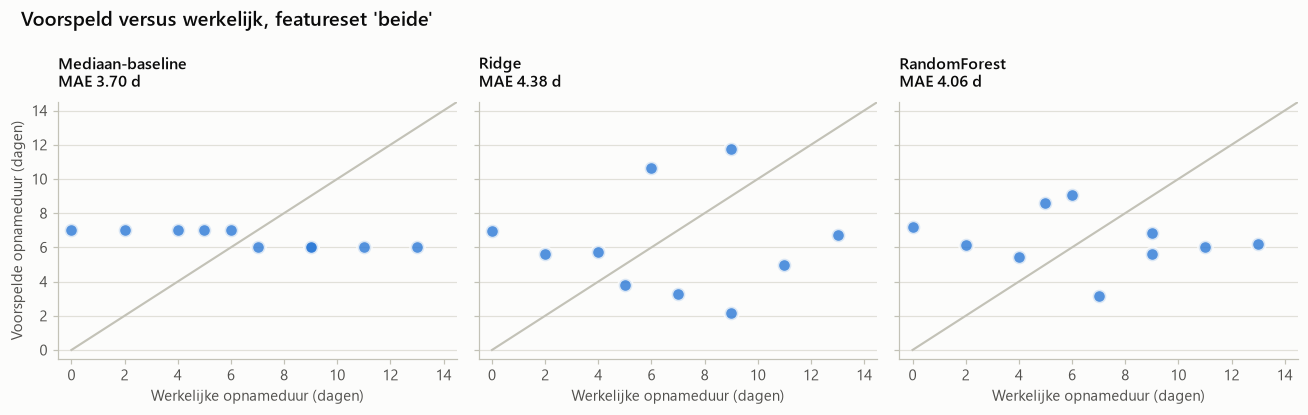

In [9]:
fig, assen = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
grens = float(modelleertabel[DOELVARIABELE].max()) + 1.5

for ax, modelnaam in zip(assen, modellen):
    uitkomst = details[(modelnaam, "beide")]
    werkelijk = uitkomst["werkelijk"]
    voorspeld = uitkomst["voorspeld"]

    ax.plot([0, grens], [0, grens], color=AS, linewidth=1.4, zorder=2)
    ax.scatter(werkelijk, voorspeld, s=80, color=BLAUW, alpha=0.8,
               edgecolor=SURFACE, linewidth=2, zorder=3)

    ax.set_title(f"{modelnaam}\nMAE {uitkomst['MAE_dagen']:.2f} d", fontsize=10.5)
    ax.set_xlabel("Werkelijke opnameduur (dagen)")
    ax.set_xlim(-0.5, grens)
    ax.set_ylim(-0.5, grens)
    stijl_as(ax, "y")
    hele_dagen(ax, "x")
    hele_dagen(ax, "y")

assen[0].set_ylabel("Voorspelde opnameduur (dagen)")
fig.suptitle("Voorspeld versus werkelijk, featureset 'beide'", x=0.02, ha="left",
             fontsize=13, fontweight="semibold", color=INK)
fig.tight_layout()
plt.show()

Kijk naar de spreiding van de punten langs de **verticale** as. De baseline is één vlakke
lijn — die voorspelt per definitie altijd hetzelfde. De getrainde modellen bewegen wel, maar
niet in de richting van de diagonaal: ze raden mee met de ruis. Een lange opname wordt niet
herkend als lang.

Dat is de eerlijke samenvatting van deze dataset: er zit geen signaal in dat met 10
waarnemingen te vinden is.

---

## 5. Conclusie

**Wat we nu weten**

- De pijplijn werkt van ruwe Excel tot out-of-fold voorspelling, en is reproduceerbaar.
- Geen enkel model verslaat de mediaan-baseline. Bij 10 opnames en 22 kolommen is dat het
  verwachte resultaat.
- De onderzoeksvraag — voegt NANDA/NOC iets toe bovenop ICD-10? — is hiermee **niet**
  beantwoord. Het verschil tussen de featuresets valt volledig binnen de ruis.

**Wat we hier níét uit mogen concluderen**

- Niet: "zorgplannen voorspellen de opnameduur niet." Dat is niet getoetst; er is alleen te
  weinig data om het te kunnen zien.
- Niet: "Ridge werkt beter dan RandomForest" (of omgekeerd). Met deze N is de volgorde van de
  modellen toeval; draai het met een andere `random_state` en hij kan omdraaien.

**Checklist voor de volledige dataset (~25.000 opnames)**

1. Wissel `LeaveOneGroupOut` voor `GroupKFold(n_splits=5)` in `src/modellering.py` — met
   duizenden patiënten is leave-one-out onnodig duur. Dat is één regel.
2. Voeg `HistGradientBoostingRegressor` toe aan het dictionary met modellen; dat is bij
   tabeldata meestal de sterkste eerste keus.
3. Overweeg `log1p` op de doelvariabele en terugrekenen bij de evaluatie, omdat opnameduur
   rechtsscheef is.
4. Zet `min_voorkomens` in `build_dag0_diagnose_dummies` op bijvoorbeeld 25, anders krijg je
   honderden dummy-kolommen die elk één keer voorkomen.
5. Doe hyperparameter-tuning in een **geneste** cross-validatie, niet op dezelfde folds waarop
   je rapporteert.
6. Kijk apart naar opnames met `heeft_dag0_meting == False`: sluit je die uit, of voorspel je
   ze met de baseline?
7. Pas dán de vergelijking `icd10` versus `beide` lezen als antwoord op de onderzoeksvraag.

**En vraag ondertussen om de echte opnamedatums.** Zolang `Opnameduur_dagen` het verschil is
tussen de eerste en de laatste meting, voorspel je deels het meetgedrag van de afdeling in
plaats van de opnameduur van de patiënt. Dat is de grootste kwaliteitswinst die buiten de code
ligt.